# Segmentación de imágenes a binaria — Actividad 5 (Corte 3)

**Sistemas de Visión Artificial · Maestría en Inteligencia Artificial · UPMH**
Víctor Manuel Santos Martínez (253220020) · Dr. Ernesto García Amaro

Este cuaderno segmenta dos imágenes de 256×256 —`PVC1.JPG` y `PVC2.JPG`, cada
una con **una hoja de planta sobre un fondo de concreto gris**— hasta obtener,
por cada una, una **imagen binaria** producto del preprocesamiento. El objetivo
es documentar, etapa por etapa, el pipeline que lleva a una segmentación óptima,
y justificar cada decisión a nivel de ingeniería de visión.

La tesis que organiza todo el trabajo: segmentar aquí es **separar lo cromático
de lo acromático**. El concreto es gris —sus canales R, G y B valen casi lo
mismo, así que su saturación y su exceso de verde son cercanos a cero—; la hoja
es croma pura. Esa asimetría es la palanca del pipeline.

## 1. Preparación del entorno

Se trabaja con OpenCV, NumPy y Matplotlib. Las etapas del pipeline viven en los
módulos de `src/` (`preprocesamiento`, `segmentacion`, `pipeline`,
`visualizacion`), de modo que el cuaderno sólo orquesta y explica.

In [1]:
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import preprocesamiento as pre
from src import segmentacion as seg
from src.pipeline import ParametrosPipeline, ejecutar

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

def mostrar(imgs, titulos, cmap=None, figsize=(12, 4)):
    fig, axes = plt.subplots(1, len(imgs), figsize=figsize)
    if len(imgs) == 1:
        axes = [axes]
    for ax, img, t in zip(axes, imgs, titulos):
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap=cmap or "gray", vmin=0, vmax=255)
        ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

OpenCV 5.0.0 | NumPy 2.5.3


PVC1 (256, 256, 3) | PVC2 (256, 256, 3)


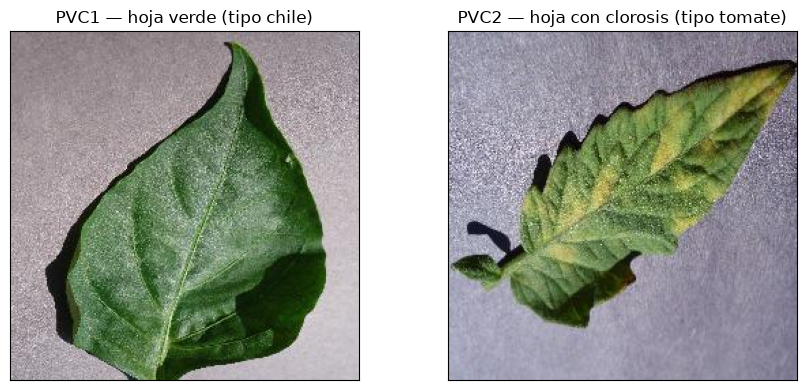

In [2]:
IMAGENES = RAIZ / "imagenes"
pvc1 = pre.cargar_color(IMAGENES / "PVC1.JPG")
pvc2 = pre.cargar_color(IMAGENES / "PVC2.JPG")
print("PVC1", pvc1.shape, "| PVC2", pvc2.shape)
mostrar([pvc1, pvc2],
        ["PVC1 — hoja verde (tipo chile)", "PVC2 — hoja con clorosis (tipo tomate)"],
        figsize=(9, 4))

Ambas imágenes comparten estructura: una hoja centrada y un concreto gris
texturizado de fondo. Pero difieren en lo que importa para segmentar por color:
**PVC1** es una hoja verde oscura y homogénea, con una franja en sombra en el
borde inferior; **PVC2** es una hoja aserrada con **clorosis** —amarilleamiento—
y nervaduras marcadas. Esa diferencia cromática hará que cada hoja pida un canal
discriminante distinto.

## 2. Etapa clásica de control: escala de grises

La primera etapa del preprocesamiento clásico es el cambio a escala de grises
por luminancia $Y = 0.299R + 0.587G + 0.114B$. Aquí cumple un papel
**diagnóstico**: muestra que la intensidad por sí sola *no* separa la hoja del
fondo. En PVC1, la hoja oscura y el concreto de brillo medio tienen histogramas
de gris que se solapan, y la franja de hoja en sombra es tan oscura como las
zonas oscuras del concreto. Esto justifica abandonar el gris y pasar a un canal
**cromático**.

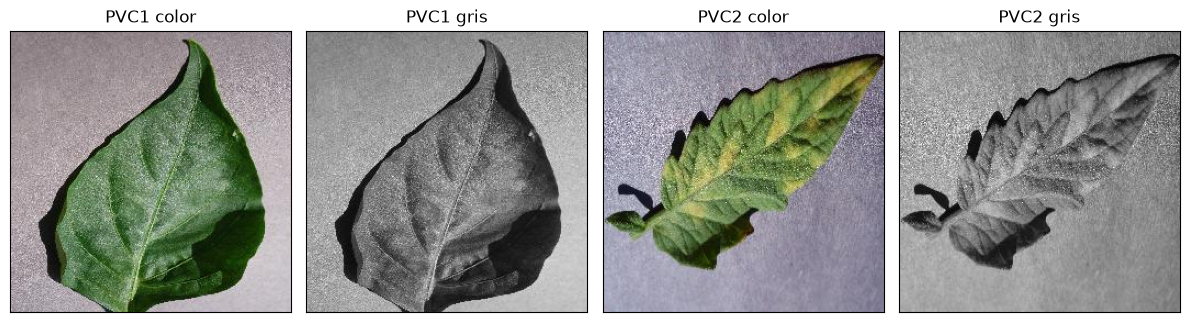

In [3]:
g1 = pre.a_grises(pvc1); g2 = pre.a_grises(pvc2)
mostrar([pvc1, g1, pvc2, g2],
        ["PVC1 color", "PVC1 gris", "PVC2 color", "PVC2 gris"], figsize=(12, 3.6))

## 3. Las tres transformadas cromáticas candidatas

Se evalúan tres discriminantes que colapsan los tres canales de color en un solo
mapa escalar donde hoja y fondo quedan separables por un umbral:

- **HSV-S** (saturación): mide *cuánto* color tiene un píxel, sin importar cuál.
  El concreto gris es acromático ($S\approx 0$) incluso en sus sombras; la hoja
  —verde o amarilla— es cromática. Es el separador más general.
- **Lab-a\***: el eje verde–rojo de CIE-Lab. Se usa $255 - a^*$ para que el verde
  quede alto. Discrimina muy bien el verde, pero es casi ciego al amarillo
  clorótico, que en $a^*$ cae cerca del neutro.
- **ExG = 2G − R − B** (Woebbecke et al., 1995): el índice de vegetación por
  excelencia. Maximiza la respuesta del verde y anula la del gris. Sobre la
  clorosis es menos tajante, porque el amarillo sube $R$ y reduce el margen
  $2G - R$.

Se umbraliza cada candidato con Otsu (tras suavizar con mediana 5×5) y se
comparan las binarias resultantes.

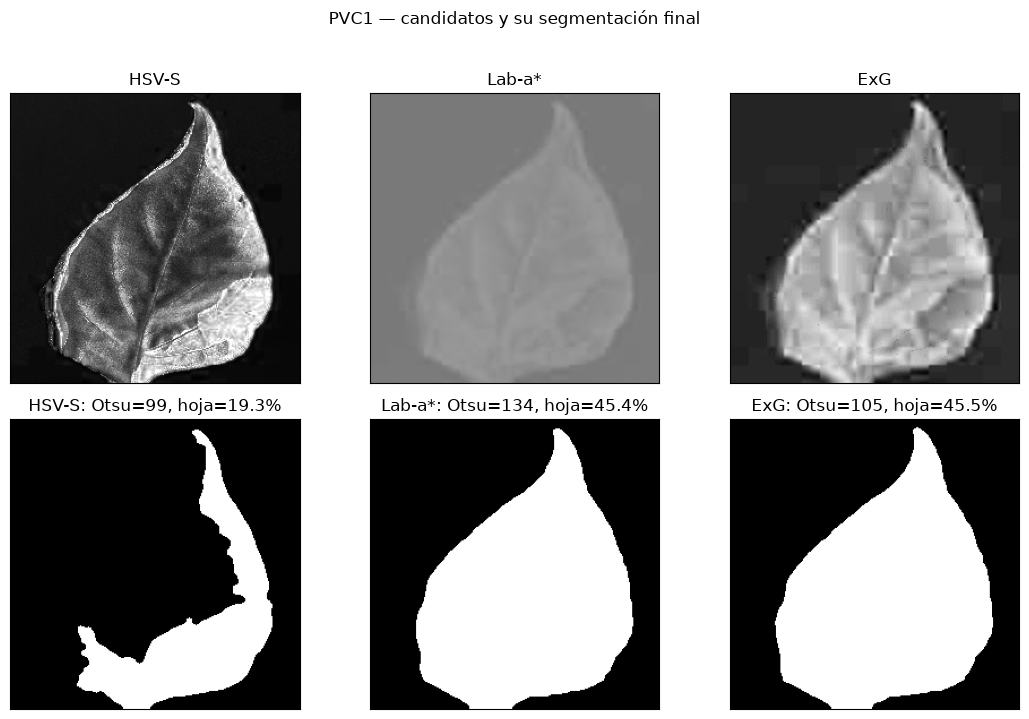

In [4]:
def comparar_canales(img, titulo):
    canales = pre.canales_discriminantes(img)
    fig, axes = plt.subplots(2, 3, figsize=(11, 7))
    for j, (k, c) in enumerate(canales.items()):
        med = pre.suavizado_mediana(c, 5)
        b, u = seg.umbral_otsu(med)
        final = seg.componente_mayor(seg.limpieza_morfologica(b))
        frac = seg.fraccion_objeto(final) * 100
        axes[0, j].imshow(c, cmap="gray", vmin=0, vmax=255)
        axes[0, j].set_title(f"{k}")
        axes[1, j].imshow(final, cmap="gray", vmin=0, vmax=255)
        axes[1, j].set_title(f"{k}: Otsu={u:.0f}, hoja={frac:.1f}%")
        for i in (0, 1):
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    fig.suptitle(titulo, y=1.02); plt.tight_layout(); plt.show()

comparar_canales(pvc1, "PVC1 — candidatos y su segmentación final")

**Lectura para PVC1.** HSV-S deja fuera la franja de hoja en sombra (el verde
muy oscuro tiene saturación baja), por lo que su máscara cubre apenas ~19 % y
recorta la hoja. **ExG y Lab-a\* cubren la hoja completa** (~45 %), porque el
verde —oscuro o no— domina el canal. Entre los dos se elige **ExG**: es el
discriminante vegetal canónico y da el blob más limpio y sólido.

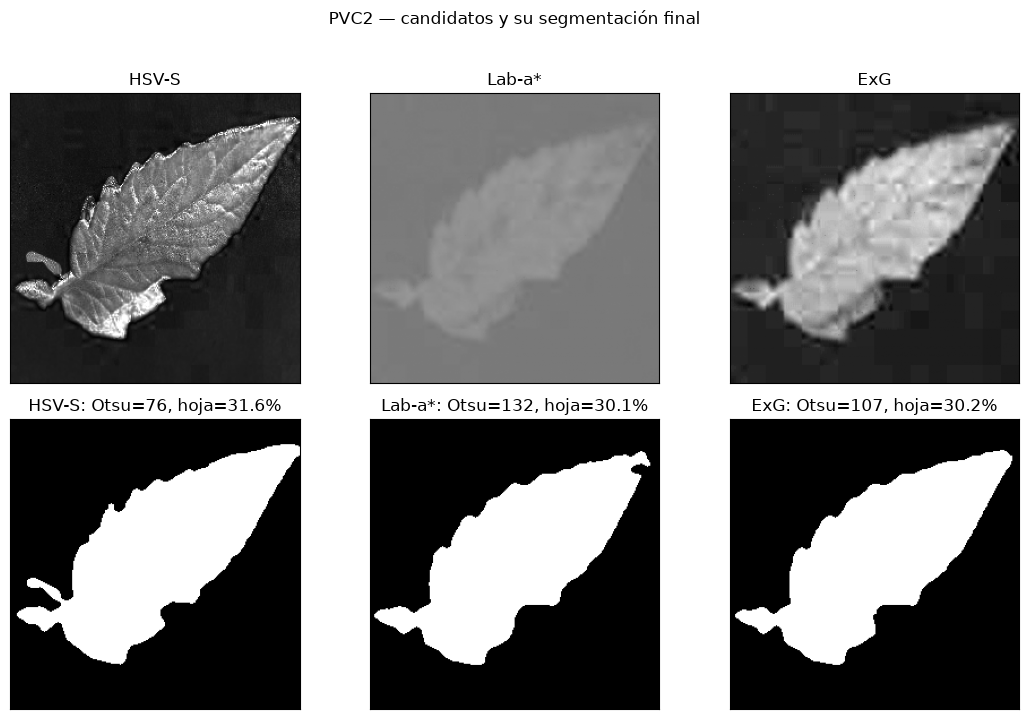

In [5]:
comparar_canales(pvc2, "PVC2 — candidatos y su segmentación final")

**Lectura para PVC2.** Aquí la clorosis cambia el veredicto. En Lab-a\* la hoja
amarilleada apenas se despega del fondo (contraste pobre) y en ExG las zonas
amarillas pierden intensidad. **HSV-S es el más completo**: recupera tanto el
verde como el amarillo —ambos son croma— incluidos los lóbulos pequeños del
margen izquierdo. Se elige **HSV-S** para PVC2.

Esta es la lección central de la práctica: **no hay un canal universal**. El
mejor discriminante depende del color del objeto; una hoja clorótica exige un
canal sensible a cualquier croma (saturación), no a un color concreto.

## 4. Suavizado paso bajo: gaussiano frente a mediana

Se suaviza el canal discriminante *antes* de umbralizar, porque la textura del
concreto y las nervaduras meten ruido de alta frecuencia que, sin filtrar,
fragmentaría la binaria en cientos de islas. Se comparan los dos filtros del
curso: el **gaussiano** (lineal, difuminado isótropo) y la **mediana** (no
lineal). Se adopta la **mediana 5×5**: borra el moteado sal y pimienta de la
arenilla del concreto sin correr el borde de la hoja, que es justo lo que la
umbralización necesita conservar.

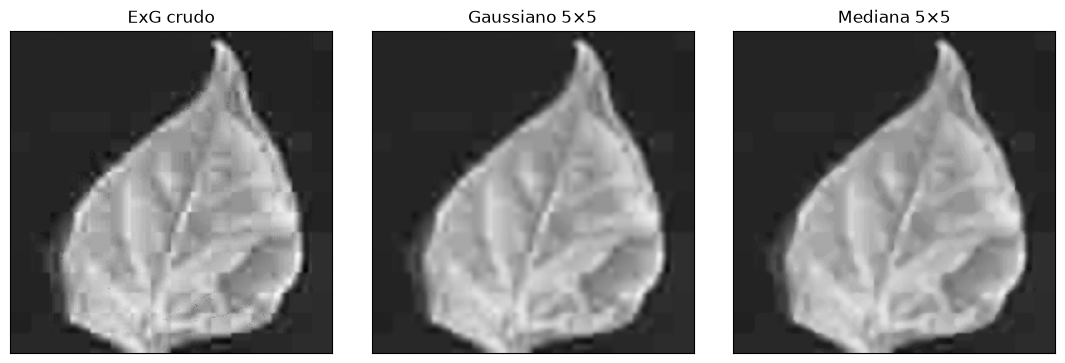

PVC1 — canal ExG


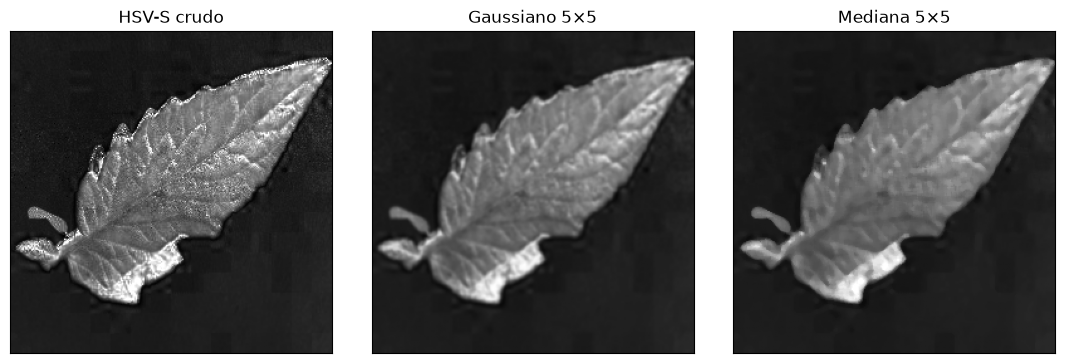

PVC2 — canal HSV-S


In [6]:
def comparar_suavizado(img, canal_key, titulo):
    c = pre.canales_discriminantes(img)[canal_key]
    g = pre.suavizado_gaussiano(c, 5); m = pre.suavizado_mediana(c, 5)
    mostrar([c, g, m], [f"{canal_key} crudo", "Gaussiano 5×5", "Mediana 5×5"],
            figsize=(11, 3.6))
    print(titulo)

comparar_suavizado(pvc1, "ExG", "PVC1 — canal ExG")
comparar_suavizado(pvc2, "HSV-S", "PVC2 — canal HSV-S")

## 5. Pipeline completo por hoja

Con el canal elegido y el suavizado fijado, se ejecuta el pipeline completo. La
función `ejecutar` encadena: canal discriminante → suavizado → **Otsu** →
**apertura** (borra islas del fondo) → **cierre** (suelda grietas de las
nervaduras) → **relleno de huecos** por inundación → **componente conexa mayor**
→ verificación por contorno. Los parámetros se fijan por imagen.

In [7]:
config = {
    "PVC1": ParametrosPipeline(canal="ExG",   suavizado="mediana", k_suavizado=5,
                               r_apertura=2, r_cierre=3),
    "PVC2": ParametrosPipeline(canal="HSV-S", suavizado="mediana", k_suavizado=5,
                               r_apertura=2, r_cierre=3),
}
resultados = {"PVC1": ejecutar("PVC1", pvc1, config["PVC1"]),
              "PVC2": ejecutar("PVC2", pvc2, config["PVC2"])}
for n, r in resultados.items():
    print(f"{n}: canal={r.parametros.canal:6s} Otsu={r.umbral:.0f} "
          f"hoja={seg.fraccion_objeto(r.final)*100:.1f}%")

PVC1: canal=ExG    Otsu=105 hoja=45.5%
PVC2: canal=HSV-S  Otsu=76 hoja=31.6%


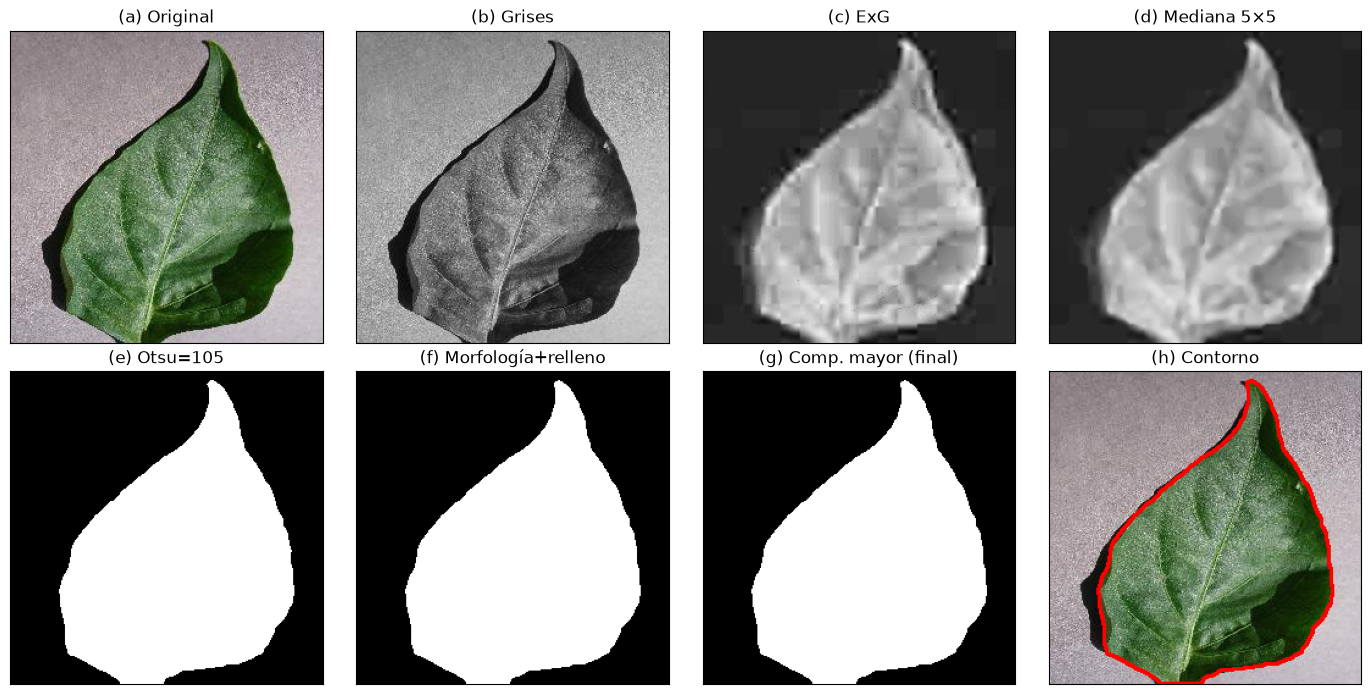

In [8]:
def montaje(res):
    p = res.parametros
    paneles = [(res.original, "(a) Original"), (res.grises, "(b) Grises"),
               (res.canal_elegido, f"(c) {p.canal}"),
               (res.suavizada, f"(d) Mediana {p.k_suavizado}×{p.k_suavizado}"),
               (res.binaria_cruda, f"(e) Otsu={res.umbral:.0f}"),
               (res.limpia, "(f) Morfología+relleno"),
               (res.final, "(g) Comp. mayor (final)"),
               (res.contorno, "(h) Contorno")]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, (img, t) in zip(axes.ravel(), paneles):
        if img.ndim == 3: ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else: ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

montaje(resultados["PVC1"])

**PVC1.** El canal ExG ya entrega una hoja casi binaria; Otsu la separa con
umbral 105 y la morfología sólo pule el borde. El resultado es una silueta
sólida y fiel —el contorno (h) calza con el borde real de la hoja, sombra
incluida—.

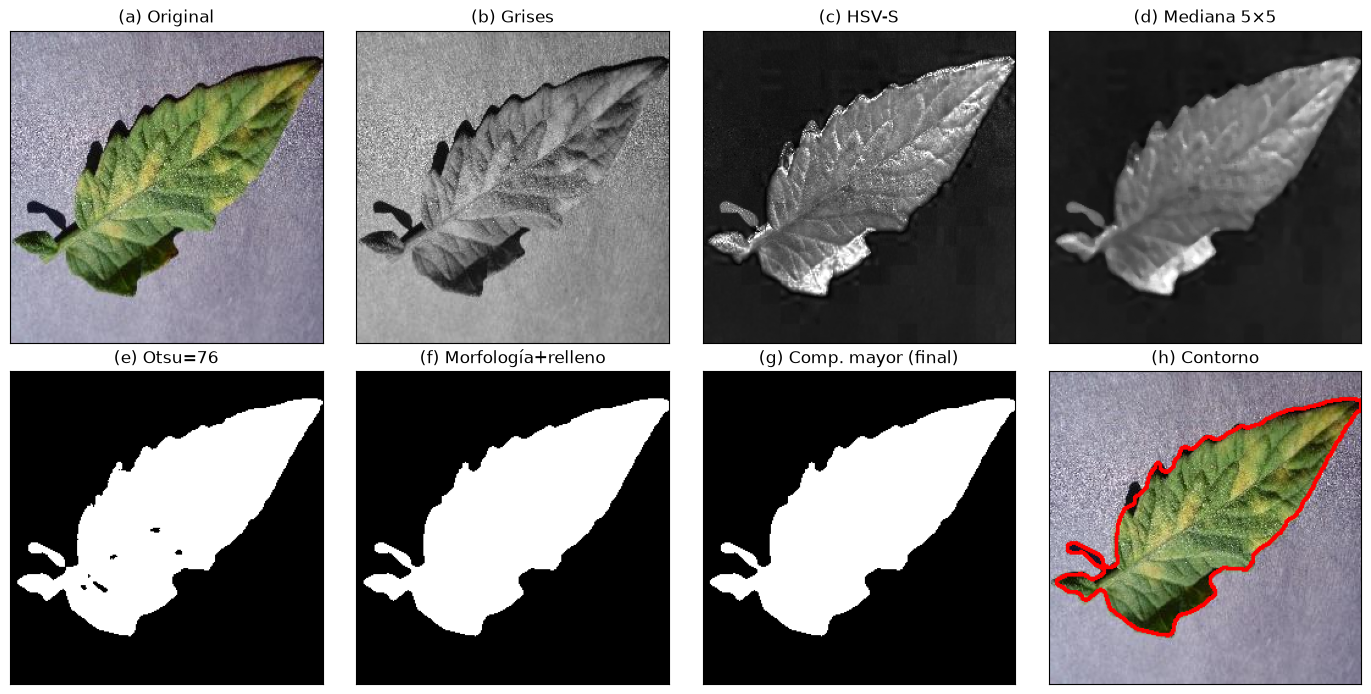

In [9]:
montaje(resultados["PVC2"])

**PVC2.** La saturación enciende la hoja clorótica completa. Tras Otsu (umbral
76), el cierre suelda las grietas que abren las nervaduras marcadas y el relleno
tapa los huecos interiores; la componente mayor descarta cualquier residuo del
fondo. El contorno sigue el margen aserrado y recupera los lóbulos del lado
izquierdo.

## 6. Entrega: las dos imágenes binarias finales

La entrega clave de la práctica. Convención: **hoja = blanco (255), fondo =
negro (0)**. Se guardan también como archivos en `salidas/`.

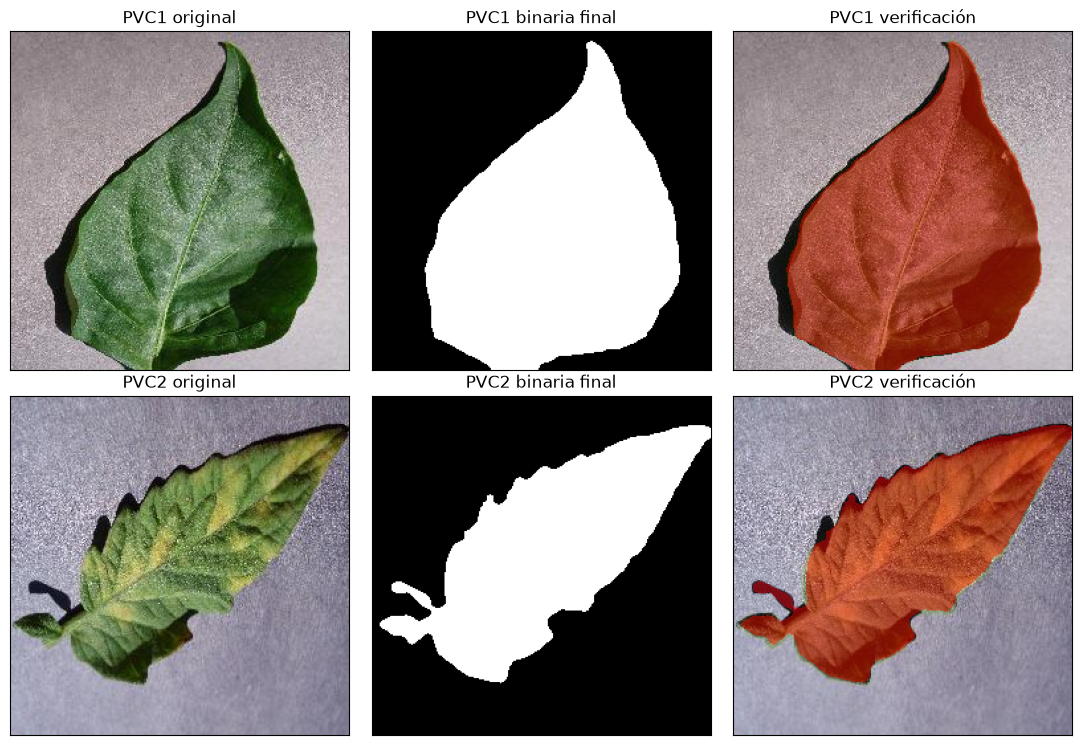

Binarias guardadas en /Users/victormanuel/Library/Mobile Documents/com~apple~CloudDocs/Maestría UMPH/Cuatrimestre 4/Sistemas de Visión Artificial/Actividades/Actividad 5/salidas


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for i, n in enumerate(["PVC1", "PVC2"]):
    r = resultados[n]
    for j, (img, t) in enumerate([(r.original, f"{n} original"),
                                   (r.final, f"{n} binaria final"),
                                   (r.overlay, f"{n} verificación")]):
        if img.ndim == 3: axes[i, j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else: axes[i, j].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(t); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
plt.tight_layout(); plt.show()

SAL = RAIZ / "salidas"; SAL.mkdir(exist_ok=True)
for n, r in resultados.items():
    cv2.imwrite(str(SAL / f"{n}_binaria.png"), r.final)
print("Binarias guardadas en", SAL)

## 7. Conclusión del cuaderno

Las dos hojas se segmentaron a binaria con el mismo esqueleto de pipeline
—grises de control, canal cromático, suavizado de mediana, Otsu, morfología y
componente mayor— cambiando únicamente el **canal discriminante**: **ExG** para
la hoja verde de PVC1 y **HSV-S** para la hoja clorótica de PVC2. La saturación
resultó el separador más robusto frente a la clorosis por responder a cualquier
croma, mientras que el exceso de verde fue imbatible sobre el verde uniforme. El
preprocesamiento clásico (grises y suavizado) no es decorativo: el gris
demuestra por qué la intensidad no basta, y el suavizado de mediana es lo que
vuelve utilizable la umbralización sobre un fondo texturizado.

El análisis extenso, las figuras finales y los pies en formato APA están en el
reporte de la actividad.